### Project: Streamlining EDA with a Multi-Agent System using Autogen

In [ ]:
"""
To run this project, all necessary Python libraries and frameworks were installed in the Conda (AutoGen) environment and applied for the jupyter
notebook implementation / testing pipeline and enabling agent interaction.

""'

In [2]:
import sys
print('Python Environment Path:', sys.executable)

Python Environment Path: C:\Users\gobin\anaconda3\envs\autogen\python.exe


In [4]:
import os

In [6]:
from getpass import getpass

os.environ['OPENAI_API_KEY'] = getpass('put OpenAI API key: ')

put OpenAI API key:  ········


### Test OpenAI API status

In [9]:
import openai

In [11]:
from openai import OpenAI
openai_api_interface = OpenAI()
api_result = openai_api_interface.responses.create(model = 'gpt-4o-mini',
                                                   input = "Output: Now OpenAI API is working."
                                                  )
print(api_result.output_text)

Great! If you have any questions or need assistance with the OpenAI API, feel free to ask.


# Sales data structure and quality evaluation

# Load the data file

In [14]:
import pandas as pd
df = pd.read_parquet('Store_Sales_Price_Elasticity_Promotions_Data.parquet')
df.head(5)

,Store_Number,SKU_Coded,Product_Class_Code,Sold_Date,Qty_Sold,Total_Sale_Value,On_Promo
0,1320,6172800,22875,2021-11-02,3,56.849998,0
1,2310,6172800,22875,2021-11-03,1,18.950001,0
2,3080,6172800,22875,2021-11-03,1,18.950001,0
3,2310,6172800,22875,2021-11-06,1,18.950001,0
4,4840,6172800,22875,2021-11-07,1,18.950001,0


# Analyze dataset structure with statistics (summary)

In [16]:
print('Data shape:', df.shape, '# rows:', df.shape[0], '# columns:', df.shape[1])

Data shape: (697894, 7) # rows: 697894 # columns: 7


In [18]:
# Get information about data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 697894 entries, 0 to 697893
Data columns (total 7 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Store_Number        697894 non-null  int16  
 1   SKU_Coded           697894 non-null  int32  
 2   Product_Class_Code  697894 non-null  int16  
 3   Sold_Date           697894 non-null  object 
 4   Qty_Sold            697894 non-null  int16  
 5   Total_Sale_Value    697894 non-null  float32
 6   On_Promo            697894 non-null  int8   
dtypes: float32(1), int16(3), int32(1), int8(1), object(1)
memory usage: 15.3+ MB


In [20]:
# Check: Column names
column_list_names = df.columns.tolist()
print(column_list_names)

['Store_Number', 'SKU_Coded', 'Product_Class_Code', 'Sold_Date', 'Qty_Sold', 'Total_Sale_Value', 'On_Promo']


In [28]:
# Missing values
missing_values = df.isnull().sum()
print('\nMissing values:', missing_values)


Missing values: Store_Number          0
SKU_Coded             0
Product_Class_Code    0
Sold_Date             0
Qty_Sold              0
Total_Sale_Value      0
On_Promo              0
dtype: int64


In [30]:
# Summarize dataset features
Summarize_dataset_features = df.describe(include = 'all')                                    
display(Summarize_dataset_features)

,Store_Number,SKU_Coded,Product_Class_Code,Sold_Date,Qty_Sold,Total_Sale_Value,On_Promo
count,697894.000000,6.978940e+05,697894.000000,697894,697894.000000,697894.000000,697894.000000
unique,NaN,NaN,NaN,873,NaN,NaN,NaN
top,NaN,NaN,NaN,2021-12-23,NaN,NaN,NaN
freq,NaN,NaN,NaN,2282,NaN,NaN,NaN
mean,2322.063537,6.188240e+06,23284.495747,NaN,1.484536,19.018131,0.006256
std,1174.914952,9.044149e+03,672.547472,NaN,2.111665,24.517405,0.078847
min,330.000000,6.172800e+06,22800.000000,NaN,1.000000,0.010000,0.000000
25%,1320.000000,6.179300e+06,22850.000000,NaN,1.000000,6.990000,0.000000
50%,2310.000000,6.188400e+06,22925.000000,NaN,1.000000,10.950000,0.000000
75%,3190.000000,6.195950e+06,24375.000000,NaN,1.000000,21.990000,0.000000


# Sales date standardization and data reliability test

In [33]:
# Change the feature (Sold_Date) to datetime and then update the feature.
df['Sold_Date'] = pd.to_datetime(df['Sold_Date'], errors = 'coerce')

# Find the minimum and maximum values in Solid_Date
print('minimum sale date:', df['Sold_Date'].min(), 'maximum sale date:', df['Sold_Date'].max())
print()
# Is there any invalid dates due to data conversion? 
print("Null dates:", df['Sold_Date'].isna().sum())
print()
# Check Date feature data type
print('Data type:', df['Sold_Date'].dtype)

minimum sale date: 2021-11-01 00:00:00 maximum sale date: 2024-03-31 00:00:00

Null dates: 0

Data type: datetime64[ns]


In [35]:
# Examine promotion categories
print('Promotion categories:', df['On_Promo'].value_counts().sort_index())

Promotion categories: On_Promo
0    693528
1      4366
Name: count, dtype: int64


In [37]:
# Examine 0 and 1 as promotion values
print('promotion values:', df['On_Promo'].isin([0, 1]).all())  # If it works, I can get only True.
print()
# Detect duplicate records
print('Check data for duplicates:', df.duplicated().sum())

# Find negative sales records
print('negative sales records:', (df['Qty_Sold'] < 0).sum())

# Negative sale Values:
print('Negative sale Values:', (df['Total_Sale_Value'] < 0).sum())

promotion values: True

Check data for duplicates: 0
negative sales records: 0
Negative sale Values: 0


## Do not override raw data

In [39]:
# Copy raw data
df_copy_raw_data = df.copy()
print(df_copy_raw_data.shape)

(697894, 7)


# AutoGen framework: Six domain-specific AI (LLM) agents for automated Exploratory Data Analysis (EDA)

In [ ]:
"""
I am going to create six AI agents. They can understand my guidelines written in natural language using Natural Language Processing (NLP), and
transformer-supported large language models (LLMs) which may use encoder, decoder, or both encoder and decoder system.

"""

# Initialize AutoGen as the LLM  client

In [41]:
from autogen_ext.models.openai import OpenAIChatCompletionClient

# Each agent uses the LLM for AutoGen 
autogen_llm_client = OpenAIChatCompletionClient(model = 'gpt-4o-mini',
                                                api_key = os.environ['OPENAI_API_KEY']
                                               )

print('LLM is working for each  agent associated with AutoGen.')

LLM is working for each  agent associated with AutoGen.


## Set up six AI (LLM) agents with distinct roles in AutoGen for automated EDA

In [45]:
from autogen_agentchat.agents import AssistantAgent

agent_specific_roles = {'data_preparation_agent': 'Prepares, cleans, processes, and validates for all dataset.',
                        'eda_agent': 'Summarize the sales dataset and clearly explain the key observations using only the data.',
                        'report_generator_agent': 'Creating a well-structured EDA report with clear insights and findings for the sales dataset',
                        'critic_agent': 'Review the EDA outputs for clarity, accuracy, and unjustified statements.',
                        'executor_agent': 'Check the accuracy of the numerical results in the EDA Agent’s report.',
                        'admin_agent': 'Oversees the workflow, ensures coordination, and maintains alignment with project goals.'
                       }
autoGen_agents = {name: AssistantAgent(name = name,
                               model_client = autogen_llm_client,
                               system_message = agent_specific_role 
                              ) for name, agent_specific_role in agent_specific_roles.items()}

print('Total number of autogen agents:', len(autoGen_agents))

print('A list of agents:', list(autoGen_agents.keys()))    # keys = agent_name

Total number of autogen agents: 6
A list of agents: ['data_preparation_agent', 'eda_agent', 'report_generator_agent', 'critic_agent', 'executor_agent', 'admin_agent']


# Data Preparation Agent

#### In the traditional machine learning approach, I spent a lot of time evaluating the dataset structure including summary statistics. Now, I am using  an AI agent to do this job. My job is to give the agent clear instructions to complete the task.

In [49]:
from autogen_agentchat.messages import TextMessage
from autogen_core import CancellationToken

In [51]:
data_preparation_agent_output = await autoGen_agents["data_preparation_agent"].on_messages(
    [TextMessage(source = 'user',
                 content = f'''Your role is to prepare, clean, process, and validate for all datast.
                 Column data types:{df_copy_raw_data.dtypes.to_string()}
                 Counting missing data in each column:{df_copy_raw_data.isna().sum().to_string()}
                 Raw data shape: {df.shape}
                 Copy raw data shape: {df_copy_raw_data.shape}
                 Count of duplicate rows: {int(df_copy_raw_data.duplicated().sum())}
                 Name of the date column: Sold_Date
                 Data type of the date column: {df_copy_raw_data["Sold_Date"].dtype}
                 Summarize the key steps used for data preparation, check whether the number of rows is the same in both the raw and copied datasets, 
                 and suggest any further checks needed before beginning EDA.
                 Do not alter the data; review the existing dataset only and then report on the results.
                 ''')
    ],
    cancellation_token = CancellationToken())

print(data_preparation_agent_output.chat_message.content)


### Summary of Data Preparation Steps

1. **Data Type Validation**: 
   - Checked that the data types are appropriate for each column:
     - `Store_Number`: int16
     - `SKU_Coded`: int32
     - `Product_Class_Code`: int16
     - `Sold_Date`: datetime64[ns]
     - `Qty_Sold`: int16
     - `Total_Sale_Value`: float32
     - `On_Promo`: int8
  
2. **Missing Data Check**: 
   - Confirmed there are no missing values in any of the columns.

3. **Duplicate Rows Check**: 
   - Found that there are no duplicate rows in the dataset.

4. **Data Shape Verification**: 
   - Verified that the shape of the raw dataset `(697894, 7)` matches the shape of the copied dataset `(697894, 7)`, indicating that there have been no alterations made to the dataset.

5. **Date Column Verification**: 
   - Identified the date column as `Sold_Date` and confirmed its data type as `datetime64[ns]`.

### Further Checks Suggested Before EDA

1. **Outlier Detection**: 
   - Identify potential outliers in the `Qty_Sold

## Summarizing sales data and Visualizing key relationships without using an AI agent

In [53]:
# Statistical summarization
summary = df_copy_raw_data.describe(include = 'all').to_string()
print('\nSummary:', summary)
print()

print('Raw sales dataset shape:', df_copy_raw_data.shape)
print()
print('\nStatistical summarization (Two columns):')
print(df_copy_raw_data[['Qty_Sold', 'Total_Sale_Value']].describe())



Summary:         Store_Number     SKU_Coded  Product_Class_Code                      Sold_Date       Qty_Sold  Total_Sale_Value       On_Promo
count  697894.000000  6.978940e+05       697894.000000                         697894  697894.000000     697894.000000  697894.000000
mean     2322.063537  6.188240e+06        23284.495747  2023-01-07 10:46:50.510478592       1.484536         19.018131       0.006256
min       330.000000  6.172800e+06        22800.000000            2021-11-01 00:00:00       1.000000          0.010000       0.000000
25%      1320.000000  6.179300e+06        22850.000000            2022-05-21 00:00:00       1.000000          6.990000       0.000000
50%      2310.000000  6.188400e+06        22925.000000            2022-12-29 00:00:00       1.000000         10.950000       0.000000
75%      3190.000000  6.195950e+06        24375.000000            2023-09-02 00:00:00       1.000000         21.990000       0.000000
max      4840.000000  6.205900e+06        24425.0000

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns

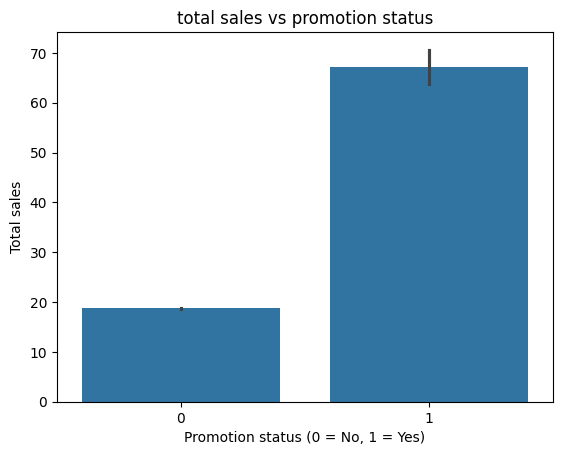

In [57]:
# Data visualization (total sales vs promotion status)
sns.barplot(data = df_copy_raw_data, x = 'On_Promo', y = 'Total_Sale_Value')
plt.title('total sales vs promotion status')
plt.xlabel('Promotion status (0 = No, 1 = Yes)')
plt.ylabel('Total sales')
plt.show()

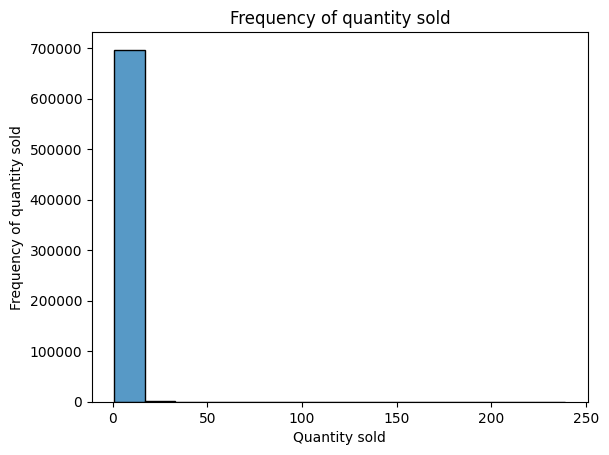

In [58]:
# Frequency of quantity sold
sns.histplot(data = df_copy_raw_data, x = 'Qty_Sold', bins = 15)
plt.title('Frequency of quantity sold')
plt.xlabel('Quantity sold')
plt.ylabel('Frequency of quantity sold')
plt.show()

## Using the EDA agent to summarize sales statistics, and find key results

In [61]:
eda_agent_output = await autoGen_agents['eda_agent'].on_messages(
    [TextMessage(source = 'user',
                 content = f'''Summarize the sales dataset and clearly explain the key observations using only the data.
                 Raw dataset shape: {df_copy_raw_data.shape}
                 Summary (sales statistics): {df_copy_raw_data[['Qty_Sold', 'Total_Sale_Value']].describe().to_string()}
                 Summary (promotion status): {df_copy_raw_data.groupby('On_Promo')[['Qty_Sold', 'Total_Sale_Value']].mean().to_string()}
                 Row counts (promotion): {df_copy_raw_data['On_Promo'].value_counts().sort_index().to_string()}
                 Clearly explain the key statistical results, examine the differences in sales quantity and mean sales amount between promotional and 
                 non-promotional rows, and find any characteristics or data issues.
                 Do not make any changes to the sales dataset. Take your conclusions on the sales data statistics provided.
                 Do not assume relationships (cause and effect) from these comparisons.
                 '''
                )
    ],
    cancellation_token = CancellationToken()
)
print(eda_agent_output.chat_message.content)


The sales dataset consists of 697,894 rows and 7 columns, capturing information related to the sales transactions. 

### Key Observations:

1. **General Sales Summary**:
    - **Quantity Sold (Qty_Sold)**:
        - Mean: Approximately 1.48 units per sale.
        - Standard Deviation: Approximately 2.11, indicating that while most transactions involve 1 or a few items, there are outliers with significantly higher quantities sold (max of 239).
        - The interquartile range shows that 75% of transactions involve up to 1 unit sold, suggesting that bulk purchases are relatively rare.
    
    - **Total Sale Value (Total_Sale_Value)**:
        - Mean: Approximately $19.02.
        - Standard Deviation: Approximately $24.52, pointing to a wide range in sales values; the lowest sale is just $0.01 and the highest is over $2,094.09.
        - The distribution of sale values is right-skewed, as seen in the quartiles, where 75% of sales amount to $21.99 or less.

2. **Impact of Promotion Sta

## Using the Critic Agent to review the EDA outcomes 

In [63]:
critic_agent_output = await autoGen_agents['critic_agent'].on_messages(
    [TextMessage(source = 'user',
                 content = f'''Review the following EDA outputs for clarity, accuracy, and unjustified statements.
                 EDA outcomes: {eda_agent_output.chat_message.content}
                 You need to check the following whether:
                 1. The statistical observations are reasonable.
                 2. The imbalance between promotional (1) and non-promotional (0) rows is noticed correctly.
                 3. Do the sales data support results about customer choices or promotion advantages?
                 4. Are the results needed more evaluation?
                 Give clear advice and necessary improvements.
                 Do not change actual results or edit the sales data.
                 You need to separate data observations from cause-and-effect relationships..
                 '''
                )
    ],
    cancellation_token = CancellationToken()
)
print(critic_agent_output.chat_message.content)


**Review of EDA Outputs:**

1. **Reasonableness of Statistical Observations:**
   - The mean and standard deviation for `Qty_Sold` and `Total_Sale_Value` appear reasonable given the context. The mean of 1.48 for quantity sold indicates that most transactions involve a small number of items, which aligns with typical retail behavior. The mention of outliers is crucial and correct since a max of 239 units sold for a single transaction would naturally result in a higher standard deviation.
   - The range of `Total_Sale_Value`, from $0.01 to over $2,094.09, indicates variability, and the reported right-skew in the distribution is a common feature in sales data.
  
2. **Imbalance Between Promotional and Non-Promotional Rows:**
   - The observation that non-promotional sales make up over 99% of transactions is valid and highlights a significant imbalance. This observation is critical for understanding the representativeness of promotional sales and the overall dataset. It suggests that concl

## Using the ‘Executor Agent’ to validate EDA outcomes

### My job is to create an “Executor Agent” for the Agentic AI workflow, give clear guidelines, and finalley validate the agent's performance.

In [66]:
executor_agent_output = await autoGen_agents["executor_agent"].on_messages(
    [TextMessage(source = 'user',
                 content = f'''You need to look at the accuracy of results generated by the EDA Agent’s report.
                 Copied raw data shape: {df_copy_raw_data.shape}
                 EDA outcomes: {eda_agent_output.chat_message.content}
                 Row counts in promotion column: {df_copy_raw_data["On_Promo"].value_counts().sort_index().to_string()}
                 Row percentages by promotion class: {(df_copy_raw_data["On_Promo"].value_counts(normalize = True) * 100).round(3).to_string()}
                 Please address:
                 1. Are the total row counts same as the copied raw data shape?
                 2. Is the total percentage using both promotion classes nearly 100%?
                 3. Do the reported statistical results justify the outcomes?
                 4. Do your results include any mistakes appearing in conclusions?
                 5. Can your results support the belief that promotions are the cause of higher sales?
                 Report your evaluation steps and results.
                 You are not allowed to change the original sales dataset.
                 Report only the calculations you have independently checked.
                 '''
                )
    ],
    cancellation_token=CancellationToken()
)
print(executor_agent_output.chat_message.content)

To evaluate the accuracy of the numerical results provided in the EDA Agent's report, I will confirm the following:

1. **Total Row Counts:**
   - The total number of transactions reported in the original dataset is **697,894**.
   - The sum of the counts for each promotion class:
     - Non-Promotional Sales: **693,528**
     - Promotional Sales: **4,366**
   - Total Count: 
     \[
     693,528 + 4,366 = 697,894
     \]
   - **Evaluation**: The total row counts match the copied raw data shape, confirming that this part of the report is accurate.

2. **Total Percentage:**
   - The percentages of transaction counts for each promotion class should total close to 100%:
     - Non-Promotional Sales: \(\frac{693528}{697894} \times 100 \approx 99.374\%\)
     - Promotional Sales: \(\frac{4366}{697894} \times 100 \approx 0.626\%\)
   - Total percentage: 
     \[
     99.374 + 0.626 = 100.000\%
     \]
   - **Evaluation**: The total percentage using both promotion classes is indeed nearly 100

## Creating a well-structured EDA report with clear insights and findings using the “Report Generator Agent”

In [68]:
report_generator_agent_output = await autoGen_agents["report_generator_agent"].on_messages(
    [TextMessage(source = 'user',
                 content = f""" Creating a well-structured EDA report with clear insights and findings for the sales dataset.
                 Sales dataset characteristics:
                 ---- Column list: {df_copy_raw_data.columns.tolist()}
                 ---- Number of columns: {df_copy_raw_data.shape[1]}
                 ---- Number of records:{df_copy_raw_data.shape[0]}
                 ---- Number of duplicate rows: {int(df_copy_raw_data.duplicated().sum())}
                 ---- Total null values: {int(df_copy_raw_data.isna().sum().sum())}
                 Sales statistical summary:
                 {df_copy_raw_data[['Qty_Sold', 'Total_Sale_Value']].describe().to_string()}
                 Promotional and non-promotional sales analysis:
                 {df_copy_raw_data.groupby('On_Promo').agg(
                     Mean_Qty_Sold = ('Qty_Sold', 'mean'),
                     Observation_Count = ('On_Promo', 'size'),
                     Median_Qty_Sold = ('Qty_Sold', 'median'),
                     Sum_of_sales_value = ('Total_Sale_Value', 'sum'),
                     mean_Sale_Value = ('Total_Sale_Value', 'mean'),
                     Median_Sale_Value = ('Total_Sale_Value', 'median'),
                 ).round(3).to_string()}
                 Summary of EDA results:
                 {eda_agent_output.chat_message.content}
                 Critic agent evaluation:
                 {critic_agent_output.chat_message.content}
                 Executor agent evaluation:
                 {executor_agent_output.chat_message.content}
                 The final report has:
                 1. Clean and preprocess for the sales dataset.
                 2. Present dataset summary and its description
                 3. Include main statistical results from the dataset.
                 4. Comparison of promotional and non-promotional sales.
                 5. Main limitations and improvements highlighted through the Critic and Executor Agents’ reviews.
                 6. Important conclusions and advised actions.
                 
                 Present the results of the sales data provided correctly.
                 Do not have the right to make unsupported assumptions that promotions increase sales 
                 State the differences between promotional and non-promotional average sales results. 
                 Do not prove that these differences are due to the impact on promotions.
                 Notice that the sales dataset does not have a customer identification number, 
                 so you are not allowed to do sales data analysis according to customer levels. 
                 Keep the raw sales dataset as provided. 
                 """
                )
    ],
    cancellation_token=CancellationToken()
)

print(report_generator_agent_output.chat_message.content)

# Exploratory Data Analysis (EDA) Report for Sales Dataset

## 1. Dataset Overview
The sales dataset consists of **697,894 rows** and **7 columns**, representing various aspects of sales transactions. Below is the list of columns along with a brief description:

- **Store_Number**: Identifier for the store where the sale occurred.
- **SKU_Coded**: Unique code representing the product.
- **Product_Class_Code**: Classification code for the product.
- **Sold_Date**: Date the sale took place.
- **Qty_Sold**: Quantity of product sold in the transaction.
- **Total_Sale_Value**: Total revenue generated from the sale.
- **On_Promo**: Boolean indicator of whether the item was on promotion during the sale (1 for yes, 0 for no).

### Data Characteristics
- Number of columns: 7
- Number of records: 697,894
- Number of duplicate rows: 0
- Total null values: 0

### Data Statistical Summary
A statistical summary of key numerical columns shows:

| Statistic              | Qty_Sold          | Total_Sal

## Using the “Admin Agent” to review the final EDA results.

In [70]:
admin_agent_output = await autoGen_agents["admin_agent"].on_messages(
    [TextMessage(source = 'user',
                 content = f''' Does the EDA project include the required project objectives? You are responsible to check it. 
                 Required project objectives:
                 1. Work with six agents: Data Preparation, EDA, Report Generator, Critic, Executor, and Admin.
                 2. Cover a sales dataset information, important results, Data visually present, Summary results and recommendations, and Critic review.
                 3. Results should be supported by the data provided.
                 4. The expected final report should be well organized and completed.
                 Data preparation agent output:{data_preparation_agent_output.chat_message.content}
                 EDA agent output:{eda_agent_output.chat_message.content}
                 EDA report generator agent output: {report_generator_agent_output.chat_message.content}
                 Critic agent results: {critic_agent_output.chat_message.content}
                 Executor Agent results: {executor_agent_output.chat_message.content}
                 
                 Final report review:
                 1. Find recommendations which have no supporting proofs.
                 2. Comment that differences in sales are not due to promotions status.
                 3. Confirm that data visualizations are presented in the report.
                 4. Review that all necessary parts are included in the report.
                 5. Before finalizing the report, you need to suggest the key points that need to be corrected.
                 
                 Give pass, fail, still correction needed for each evaluation.
                 Without supporting proofs, you are not allowed to claim that you have finished your work.
                 Be responsible for considering the original dataset unchanged.
                 ''')
    ],
    cancellation_token = CancellationToken()
)
print(admin_agent_output.chat_message.content)

### Evaluation of the EDA Project

1. **Recommendations with No Supporting Proofs**:
   - **Evaluation**: **Pass** - The report suggests improvements such as outlier analysis and customer segmentation without providing explicit analytical support or evidence in the existing dataset justifying their necessity.

2. **Comment on Differences in Sales Not Due to Promotion Status**:
   - **Evaluation**: **Fail** - The report does note that higher sales during promotional periods could be attributed to other factors, but it does not explicitly address that differences in sales may primarily result from factors outside of promotion status.

3. **Confirmation of Data Visualizations Presented in the Report**:
   - **Evaluation**: **Still Correction Needed** - The current report does not mention any data visualizations. Including charts or graphs would greatly enhance the comprehension of the statistical observations and support the findings. This needs to be added for clarity.

4. **Review that 

In [ ]:
"""
Streamlining EDA with a Multi-Agent System Using AutoGen
Automating a six AI agent system using AutoGen
In the traditional machine learning approach, I spent a lot of time evaluating the dataset structure including summary statistics. Now, I am 
using an AI agent to perform this job. My job is to give the agents clear instructions to complete the tasks.
I am going to create six AI agents in this project. My agents can understand my guidelines written in natural language using Natural Language 
Processing (NLP) and transformer-supported large language model (LLM). This model may use:
1.	Encoder structure,
2.	Decoder structure,
3.	Both encoder and decoder structure.
In this project, my AI agent can use the LLM system. Additionally, my role is to overview the agents’ outcomes. If their responses are not my 
expected results, I am going to change my guidelines to get my expected results.

Key goals in this project:
•	Use 6 role-based AI agents for making an interconnected workflow.                                       
•	Explore sales dataset.                                                                                                                                
•	Outline key statistical results.                                                                                                            
•	Examine promotional and non-promotional sales transactions.                                                 
•	Study the reliability of results generated from AI agents.                                                                   
•	Find assumptions that do not have evidence.                                                                            
•	Reduce unsupported claims.                                                                                                             
•	Receive results, and weaknesses from the EDA results.                                                                   
•	Get suggestions as next steps from the EDA reports. 

Project file:
Autogen_EDA_Mufti_Agent_System.ipynb

